In [30]:
import numpy as np
import math
import cv2
import matplotlib.pyplot as plt
from collections import deque
print("Библиотеки загружены")

Библиотеки загружены


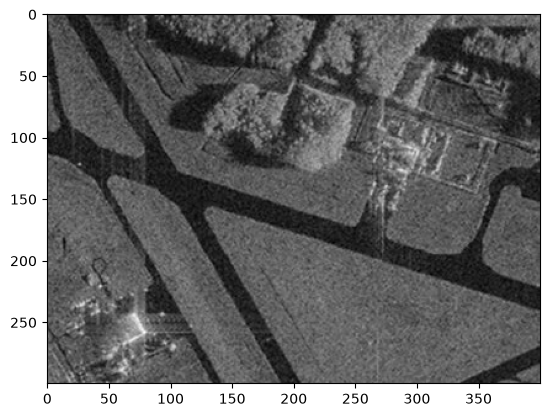

In [33]:
image = cv2.imread('sar_1.jpg')
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
plt.imshow(image_gray, cmap='gray')

Text(0.5, 1.0, 'Выделенный газон (T=20)')

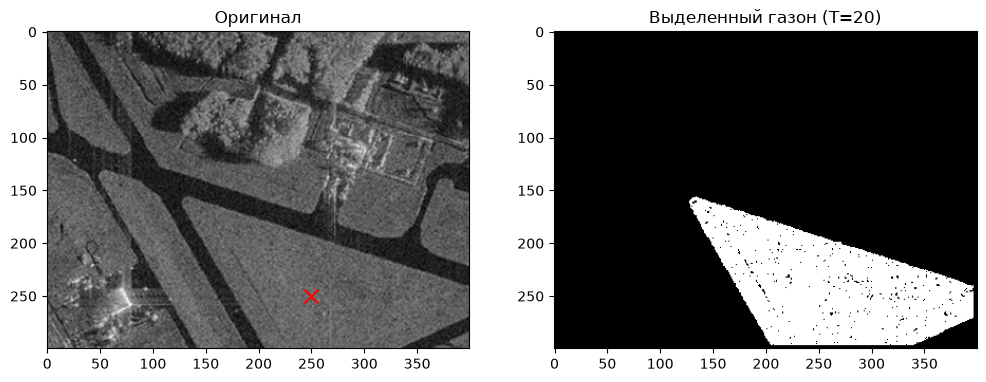

In [4]:
# 1. Подберите парамтеры алгоритма разрастания регионов так, чтобы был выделен весь участок газона.

# критерий однородности(сравнение со средним значением)
def homo_average(img, mask, point, T):
    av_val = img[mask > 0].sum() / np.count_nonzero(img[mask > 0])
    if abs(av_val - img[point]) <= T:
        return True
    return False


# функция разрастания регионов
def region_growing(image, seed_point, homo_fun, r, T):
    mask = np.zeros(image.shape, np.uint8)
    mask[seed_point] = 1
    count = 1
    
    while count > 0:
        count = 0
        local_mask = np.zeros(image.shape, np.uint8)
        for i in range(r, image.shape[0] - r):
            for j in range(r, image.shape[1] - r):
                if mask[i, j] == 0 and mask[i - r:i + r, j - r:j + r].sum() > 0:
                    if homo_fun(image, mask, (i, j), T):
                        local_mask[i, j] = 1
        count = np.count_nonzero(local_mask)
        mask += local_mask
        
    return mask * 255

# подбор параметров
# точка внутри газона
seed_point = (250, 250) 

# радиус соседства
r = 3 

# порог однородности T
T = 20 

mask = region_growing(image_gray, seed_point, homo_average, r, T)

plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(image_gray, cmap='gray')
plt.scatter(seed_point[1], seed_point[0], color='red', marker='x', s=100)
plt.title(f'Оригинал')

plt.subplot(1, 2, 2)
plt.imshow(mask, cmap='gray')
plt.title(f'Выделенный газон (T={T})')

Text(0.5, 1.0, 'Критерий: разница с соседом (T=1)')

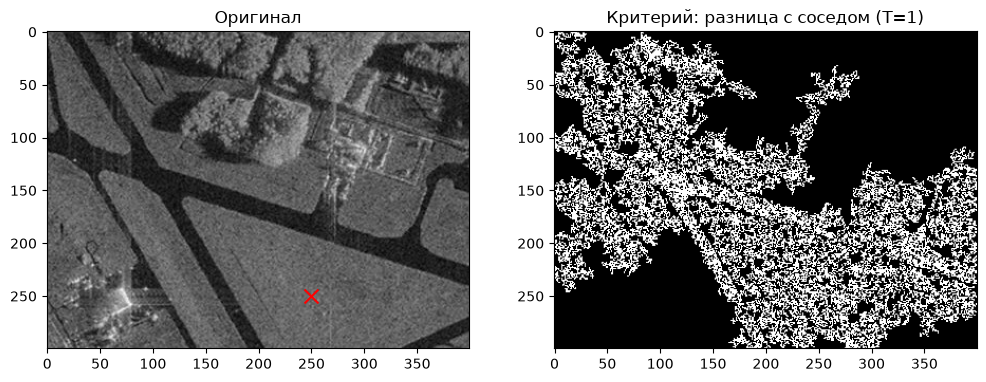

In [45]:
# 2. Реализуйте вычисление критерия однородности, отличного от представленного. Сравните результаты.
# критерий 2: разница между соседними пикселями
def homo_neighbor(img, seed_val, point, T):
    y, x = point
    # 4 соседа
    neighbors = [(y-1, x), (y+1, x), (y, x-1), (y, x+1)]
    
    for ny, nx in neighbors:
        #  сосед не выходит за границы изображения
        if 0 <= ny < img.shape[0] and 0 <= nx < img.shape[1]:
            # сравнение текущего пикселя с соседом
            if abs(int(img[y, x]) - int(img[ny, nx])) <= T:
                return True
    return False

# функция разрастания регионов через очередь
def region_grow_neighbor(image, seed_point, r, T):
    height, width = image.shape[:2]
    mask = np.zeros((height, width), dtype=np.uint8)
    mask[seed_point] = 1
    queue = deque([seed_point])
    
    while queue:
        cy, cx = queue.popleft()
        y_min, y_max = max(0, cy - r), min(height, cy + r + 1)
        x_min, x_max = max(0, cx - r), min(width, cx + r + 1)
        
        for i in range(y_min, y_max):
            for j in range(x_min, x_max):
                if mask[i, j] == 0:
                    if mask[y_min:y_max, x_min:x_max].sum() > 0:
                        if homo_neighbor(image, image[seed_point], (i, j), T):
                            mask[i, j] = 1
                            queue.append((i, j))
    return mask * 255

# 4. Параметры 
seed_point = (250, 250) 
r = 1  # смотрим только соседей
T = 1

mask = region_grow_neighbor(image_gray, seed_point, r, T)

plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(image_gray, cmap='gray')
plt.scatter(seed_point[1], seed_point[0], color='red', marker='x', s=100)
plt.title('Оригинал')

plt.subplot(1, 2, 2)
plt.imshow(mask, cmap='gray')
plt.title(f'Критерий: разница с соседом (T={T})')

In [ ]:
# ВЫВОД
# исходный метод показал результат лучше, так как с его помощью была выделена целостная область газона, когда в случае второго критерия границы размыты

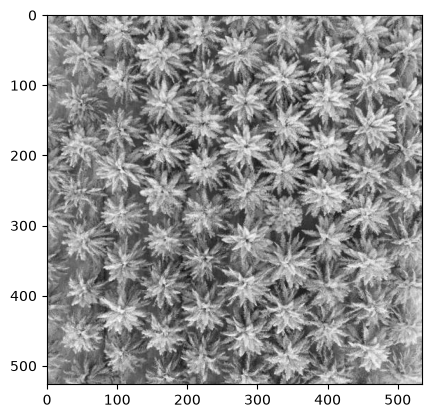

In [47]:
image_palm = cv2.imread('palm_1.JPG')
image_palm_gray = cv2.cvtColor(image_palm, cv2.COLOR_BGR2GRAY)
plt.imshow(image_palm_gray, cmap='gray')

Найдено пальм: 85


Text(0.5, 1.0, 'Watershed (Найдено: 85)')

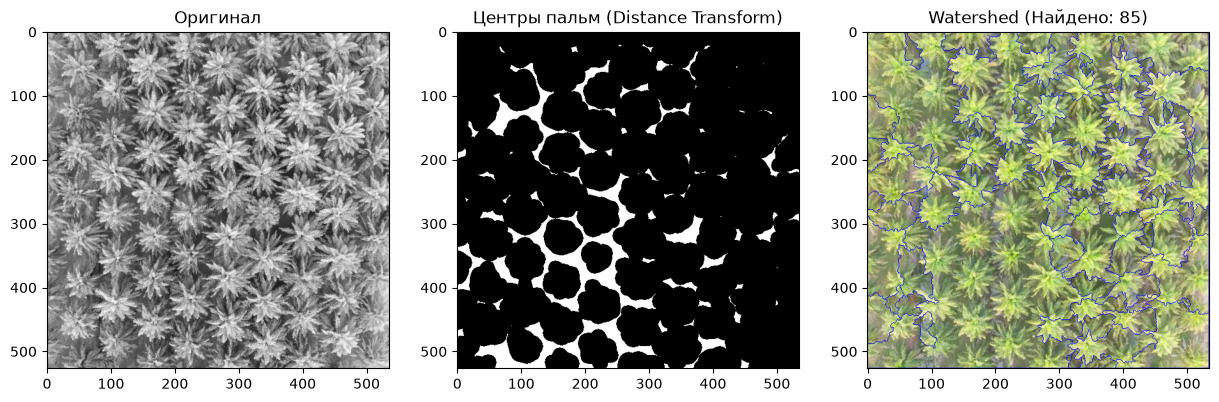

In [48]:
# размытие
blur = cv2.GaussianBlur(image_palm_gray, (25, 25), 0)

# бинаризация Оцу(кроны пальм стали белыми, а фон черным)
_, thresh = cv2.threshold(blur, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

# Distance Transform 
# расстояние от каждого пикселя до ближайшего фона
dist = cv2.distanceTransform(thresh, cv2.DIST_L2, 5)

# уверенный передний план(берем только центры, где расстояние до фона максимально)
_, sure_fg = cv2.threshold(dist, 0.37 * dist.max(), 255, cv2.THRESH_BINARY)
sure_fg = sure_fg.astype(np.uint8)

# центр кроны
_, markers = cv2.connectedComponents(sure_fg)

# Watershed 
markers = cv2.watershed(image_palm, markers)

# -1 это границы
n_palms = markers.max() - 1
print(f"Найдено пальм: {n_palms}")

result_image = image_palm.copy()
result_image[markers == -1] = [255, 0, 0] 

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(image_palm_gray, cmap='gray')
plt.title('Оригинал')

plt.subplot(1, 3, 2)
plt.imshow(sure_fg, cmap='gray')
plt.title('Центры пальм (Distance Transform)')

plt.subplot(1, 3, 3)
plt.imshow(cv2.cvtColor(result_image, cv2.COLOR_BGR2RGB))
plt.title(f'Watershed (Найдено: {n_palms})')